In [1]:
import pandas as pd
import tensorflow

I0000 00:00:1794295725.706058    2867 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794295725.715202    2867 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794295726.443637    2867 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794295718.194500    2867 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

In [4]:
import pickle
import tensorflow as tf
import keras
dataset = pd.read_pickle('preprocessed_data.pkl')

In [3]:
type(dataset)

dict

In [35]:
model = keras.Sequential(
    [keras.layers.Dense(128,input_shape=(dataset['X_train'].shape[-1],),activation='relu'),
    keras.layers.Dropout(0.1, noise_shape=None, seed=None,),
    keras.layers.Dense(128,input_shape=(21,),activation='softmax'),
    ]
)

/home/goatman/Desktop/all_py/proiect_irn/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])


In [8]:
dataset['X_train'].shape, dataset['y_train'].shape

((1760, 7), (1760,))

In [23]:
print(dataset['y_train'].value_counts())

10    89
16    86
7     86
6     83
5     83
15    83
12    81
14    81
20    81
21    81
2     80
9     80
1     79
11    79
0     77
19    77
18    77
8     77
17    77
13    76
3     74
4     73
Name: count, dtype: int64


In [40]:
history=model.fit(dataset['X_train'], dataset['y_train'], epochs=20)


Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9534 - loss: 0.2141
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9608 - loss: 0.1898
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9676 - loss: 0.1738
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9659 - loss: 0.1610
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9642 - loss: 0.1488
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9705 - loss: 0.1357
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9676 - loss: 0.1292
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9693 - loss: 0.1209
Epoch 9/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9773 - loss: 0.1136
Epoch 10/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9801 - loss: 0.1040
Epoch 11/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9767 - loss: 0.1023
Epoch 12/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9773 - lo

In [41]:
test_loss, test_acc = model.evaluate(dataset['X_test'], dataset['y_test'], verbose=2)

print('\nTest accuracy:', test_acc)


14/14 - 0s - 5ms/step - accuracy: 0.9591 - loss: 0.1042

Test accuracy: 0.9590908885002136


In [32]:
import matplotlib.pyplot as plt


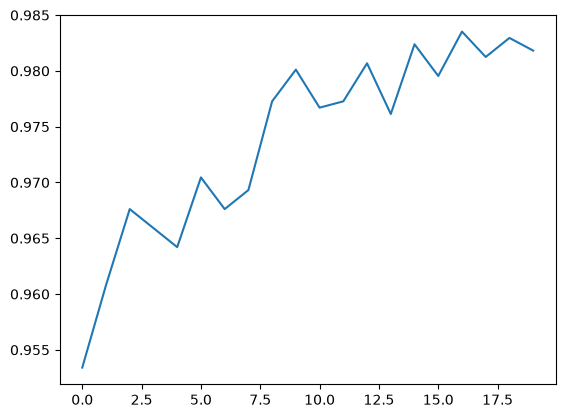

In [42]:
plt.plot(history.history['accuracy'], label='accuracy')